In [7]:
# Sel 1: data
from google.colab import drive
import os
drive.mount('/content/drive')
SRC = "/content/drive/MyDrive/data_uts_dl"
if not os.path.exists('/content/data/klasifikasi_train.npz'):
    !mkdir -p /content/data
    !cp {SRC}/*.npz /content/data/
    !cp {SRC}/klasifikasi_train_meta.csv {SRC}/klasifikasi_test_meta.csv {SRC}/clustering_meta.csv {SRC}/kamus_data.md /content/data/
    !cp {SRC}/rul_train.csv/rul_train.csv {SRC}/rul_test.csv/rul_test.csv /content/data/

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:
# Sel 2: repo (fork kamu)
from google.colab import userdata
import os
token = userdata.get('GH_TOKEN')
if not os.path.exists('/content/UTSDEEPLEARNING'):
    !git clone https://{token}@github.com/rafiptrnto/UTSDEEPLEARNING.git /content/UTSDEEPLEARNING
%cd /content/UTSDEEPLEARNING
!git config user.name "rafiptrnto"
!git config user.email "rafiputranto665@gmail.com"
!git remote add upstream https://github.com/UTSDEEPLEARNING/UTSDEEPLEARNING.git 2>/dev/null || true
!git pull upstream main

/content/UTSDEEPLEARNING
remote: Enumerating objects: 1, done.
remote: Counting objects: 100% (1/1), done.
remote: Total 1 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Unpacking objects: 100% (1/1), 899 bytes | 899.00 KiB/s, done.
From https://github.com/UTSDEEPLEARNING/UTSDEEPLEARNING
 * branch            main       -> FETCH_HEAD
   e43db9f..bb914e0  main       -> upstream/main
Updating a6d4dbe..bb914e0
Fast-forward


In [12]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
tr = np.load('/content/data/klasifikasi_train.npz')
te = np.load('/content/data/klasifikasi_test.npz')
meta = pd.read_csv('/content/data/klasifikasi_train_meta.csv')
test_meta = pd.read_csv('/content/data/klasifikasi_test_meta.csv')

print("train:", tr['gambar'].shape, " test:", te['gambar'].shape)
print(meta['kelas'].value_counts())
print(pd.crosstab(meta['lini'], meta['kelas'], normalize='index').round(3))
for kol in ['lini', 'shift']:
    print(kol, "\ntrain:", meta[kol].value_counts(normalize=True).round(3).to_dict(),
          "\ntest :", test_meta[kol].value_counts(normalize=True).round(3).to_dict())

train: (48000, 64, 64)  test: (16000, 64, 64)
kelas
normal         23888
gores           5623
noda            4773
las_dingin      4323
retak           3606
gelembung       3430
kontaminasi     2357
Name: count, dtype: int64
kelas  gelembung  gores  kontaminasi  las_dingin   noda  normal  retak
lini                                                                  
A          0.072  0.118        0.049       0.090  0.099   0.497  0.075
B          0.071  0.116        0.048       0.089  0.100   0.501  0.075
lini 
train: {'A': 0.749, 'B': 0.251} 
test : {'B': 0.6, 'A': 0.4}
shift 
train: {'malam': 0.335, 'siang': 0.334, 'pagi': 0.33} 
test : {'pagi': 0.337, 'malam': 0.334, 'siang': 0.329}


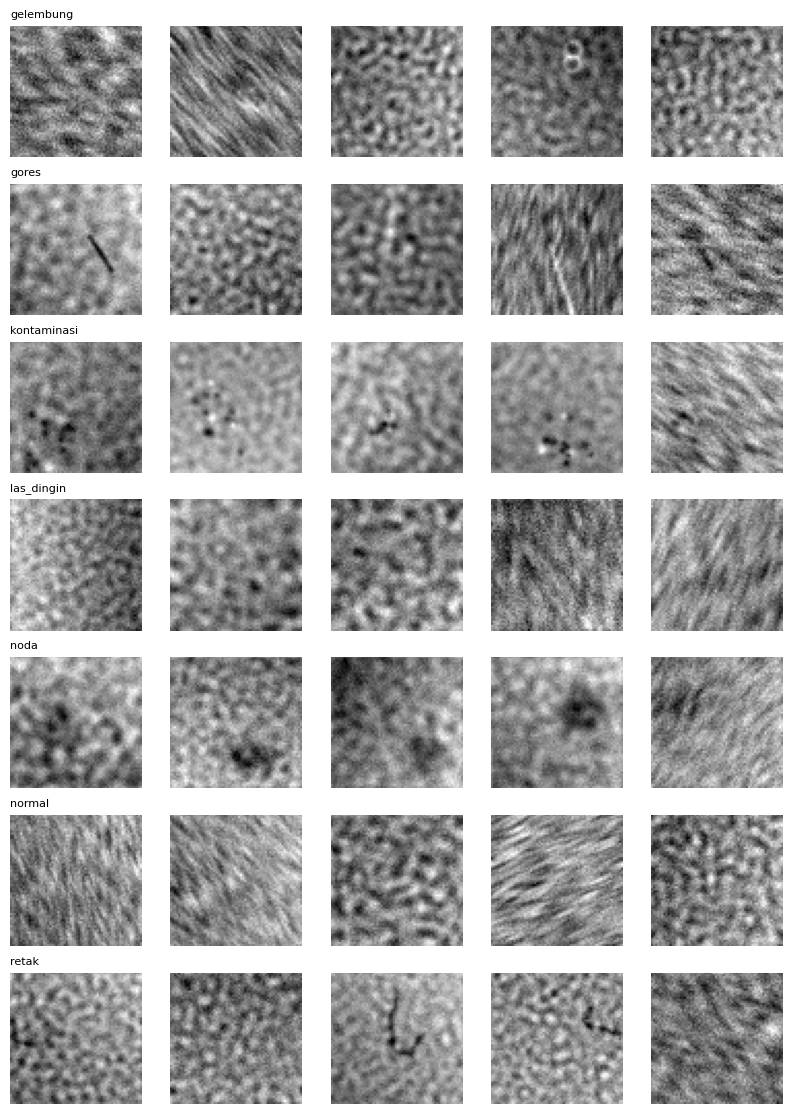

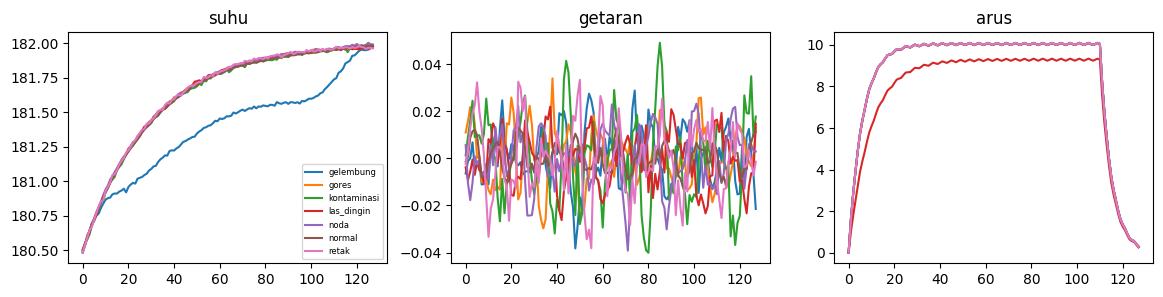

In [13]:
kelas = sorted(meta['kelas'].unique())
fig, ax = plt.subplots(len(kelas), 5, figsize=(10, 2*len(kelas)))
for i, k in enumerate(kelas):
    idx = meta.index[meta['kelas'] == k][:5]
    for j, ix in enumerate(idx):
        ax[i, j].imshow(tr['gambar'][ix], cmap='gray'); ax[i, j].axis('off')
    ax[i, 0].set_title(k, fontsize=8, loc='left')
plt.show()

sensor = tr['sensor'].astype('float32')
fig, ax = plt.subplots(1, 3, figsize=(14, 3))
for c, nama in enumerate(['suhu', 'getaran', 'arus']):
    for k in kelas:
        ax[c].plot(np.nanmean(sensor[(meta['kelas'] == k).values, c], axis=0), label=k)
    ax[c].set_title(nama)
ax[0].legend(fontsize=6)
plt.show()

In [14]:
ada_nan = np.isnan(sensor).any(axis=(1, 2))
print("unit dengan NaN:", ada_nan.mean().round(3))
print(meta.assign(nan=ada_nan).groupby('kelas')['nan'].mean().round(3))
print(meta.assign(nan=ada_nan).groupby('lini')['nan'].mean().round(3))

unit dengan NaN: 0.08
kelas
gelembung      0.080
gores          0.085
kontaminasi    0.071
las_dingin     0.077
noda           0.078
normal         0.081
retak          0.085
Name: nan, dtype: float64
lini
A    0.081
B    0.079
Name: nan, dtype: float64


In [10]:
!ls "/content/drive/MyDrive/Colab Notebooks/" | grep -i task1

task1_klasifikasi.ipynb


In [11]:
%cd /content/UTSDEEPLEARNING
!mkdir -p kode/task1_klasifikasi
!cp "/content/drive/MyDrive/Colab Notebooks/task1_klasifikasi.ipynb" kode/task1_klasifikasi/
!git add .
!git commit -m "Task 1: eksplorasi data"
!git push origin task1-eksplorasi

/content/UTSDEEPLEARNING
[task1-eksplorasi d8462b8] Task 1: eksplorasi data
 1 file changed, 1 insertion(+), 1 deletion(-)
Enumerating objects: 9, done.
Counting objects: 100% (9/9), done.
Delta compression using up to 2 threads
Compressing objects: 100% (5/5), done.
Writing objects: 100% (5/5), 1.03 KiB | 1.03 MiB/s, done.
Total 5 (delta 2), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (2/2), completed with 2 local objects.
To https://github.com/rafiptrnto/UTSDEEPLEARNING.git
   bb914e0..d8462b8  task1-eksplorasi -> task1-eksplorasi
